## NicheJepa Model training

Creator: Mohammad Vali Sanian (mohammad.sanian@helsinki.fi) (mv10@sanger.ac.uk).

Date of Creation: 16.08.2024

Date of Last Modification: 31.08.2024

# 1. Setup

## 1.1 Libraries 

In [2]:
import os
import logging

import anndata as ad
import torch
import numpy as np
import scanpy as sc
from sklearn.metrics.pairwise import cosine_similarity

from nichejepa.eval import evaluation
from nichejepa.train import train
from nichejepa.utils.config_utils import create_params_from_YAML_wandb_config, prepare_dataset
from nichejepa.utils.distributed import init_distributed
from nichejepa.utils.eval_utils import clustering_metrics, classification_metrics

## 1.2 Create params
All setup will be done in the config file. Please edit that file to continue.

In [16]:
rank=0
logging.basicConfig()
logger = logging.getLogger()
logger.setLevel(logging.INFO if rank == 0 else logging.ERROR)
params = create_params_from_YAML_wandb_config('../../../nichejepa/configs/simulated.yaml',logger)

INFO:root:Loaded parameters from YAML file.


In [17]:
params

{'data': {'batch_size': 200,
  'data_path': '/lustre/scratch126/cellgen/team361/mv10/nichejepa-reproducibility/nichejepa-reproducibility/datasets/st_data/gold/cell_neighborhood_tokenizer/sim1_1105fts_10000locs/sim1_1105fts_10000locs_read_depth_shifted_log_2210.dataset',
  'data_set_name': 'Simulated_data',
  'num_workers': 18,
  'pin_mem': True,
  'vocab_size': 1107,
  'just_cell': True,
  'just_neighborhood': True,
  'seq_len_cell': 361,
  'seq_len_neighborhood': 1091,
  'has_cls': True,
  'sample_size': 100000,
  'sample_subset': False,
  'random_state': 0,
  'stratify': False,
  'split': 0.2,
  'specific_cell_types': []},
 'emb': {'weighted_average': False,
  'average': True,
  'cls': False,
  'select_topk': False,
  'retrieve_gene': False,
  'retrieve_niche': False,
  'retrieve_cell': True,
  'gene_id': 332,
  'retrieve_position_emb': False,
  'retrieve_emb_from_layer': 2},
 'logging': {'folder': 'logs/merfish_200', 'write_tag': 'jepa'},
 'mask': {'context_mask_size': 361,
  'targe

## 1.3 Create Train,Test dataset

In [18]:
train_dataset, test_dataset = prepare_dataset(params)

## 1.4 INIT distributed (it should change later)

In [20]:
devices=['cuda:0']
world_size=1
os.environ['CUDA_VISIBLE_DEVICES'] = str(devices[rank].split(':')[-1])

logging.basicConfig()
logger = logging.getLogger()
logger.setLevel(logging.INFO if rank == 0 else logging.ERROR)

world_size, rank = init_distributed(rank_and_world_size=(rank, world_size), port=40316)
logger.info(f'Running... (rank: {rank}/{world_size})')

INFO:root:Running... (rank: 0/1)


# 2. Model Training with Cell and Neighborhood Tokens Included

## 2.1 Train Model

In [ ]:
params['data']['just_cell'] = True
params['data']['just_neighborhood'] = True
train(params, train_dataset, test_dataset)

# 3. Analysis with Cell and Neighborhood Tokens Included

## 3.1 Cell Type Average

In [21]:
params['emb']['retrieve_cell'] = True
params['emb']['retrieve_niche'] = False
params['emb']['retrieve_gene'] = False
params['emb']['weighted_average'] = False
params['emb']['average'] = True
params['emb']['cls'] = False
params['data']['incl_cell_seq'] = True
params['data']['incl_neighborhood_seq'] = True
adata = evaluation(params, train_dataset, test_dataset)

INFO:root:GeneTransformerEncoder(
  (gene_embed): Embedding(1108, 768, padding_idx=0)
  (seg_embed): Embedding(3, 768, padding_idx=0)
  (blocks): ModuleList(
    (0-2): 3 x Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=3072, out_features=768, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
)
INFO:root:Encountered exception when loading checkpoi

/nfs/users/nfs_s/sb75/.local/lib/python3.10/site-packages/torch/utils/data/dataloader.py:557: UserWarning: This DataLoader will create 18 worker processes in total. Our suggested max number of worker in current system is 4, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(_create_warning_msg(
40it [00:29,  1.35it/s]
10it [00:10,  1.05s/it]
... storing 'split' as categorical
... storing 'label_name' as categorical
... storing 'retrieve_label' as categorical
... storing 'cell_type' as categorical


AnnData has been successfully saved at: logs/Simulated_data_pred_depth_1_pred_emb_dim_768_enc_depth_3_n_targets_4_n_contexts_1_target_mask_size_19_context_mask_size_361_num_epochs_15_incl_cell_seq_incl_neighborhood_seq_total/extracted_features/cell_embedding_average.h5ad


In [22]:
adata = ad.read_h5ad("logs/Simulated_data_pred_depth_1_pred_emb_dim_768_enc_depth_3_n_targets_4_n_contexts_1_target_mask_size_19_context_mask_size_361_num_epochs_15_incl_cell_seq_incl_neighborhood_seq_total/extracted_features/cell_embedding_average.h5ad")

### 3.1.1 Feature Analysis

In [23]:
similarity_matrix = cosine_similarity(adata.obsm['jepa_emb'])
similarity_matrix

array([[1.0000002 , 0.99762243, 0.9974551 , ..., 0.9977231 , 0.9976531 ,
        0.9975964 ],
       [0.99762243, 1.0000002 , 0.9976072 , ..., 0.997716  , 0.9978496 ,
        0.9975068 ],
       [0.9974551 , 0.9976072 , 1.        , ..., 0.9976169 , 0.997377  ,
        0.9974167 ],
       ...,
       [0.9977231 , 0.997716  , 0.9976169 , ..., 1.0000001 , 0.9974593 ,
        0.9979919 ],
       [0.9976531 , 0.9978496 , 0.997377  , ..., 0.9974593 , 1.0000002 ,
        0.997308  ],
       [0.9975964 , 0.9975068 , 0.9974167 , ..., 0.9979919 , 0.997308  ,
        1.0000004 ]], dtype=float32)

### 3.1.2 Umap

/software/cellgen/team205/sb75/envs/nichejepa/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/software/cellgen/team205/sb75/envs/nichejepa/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


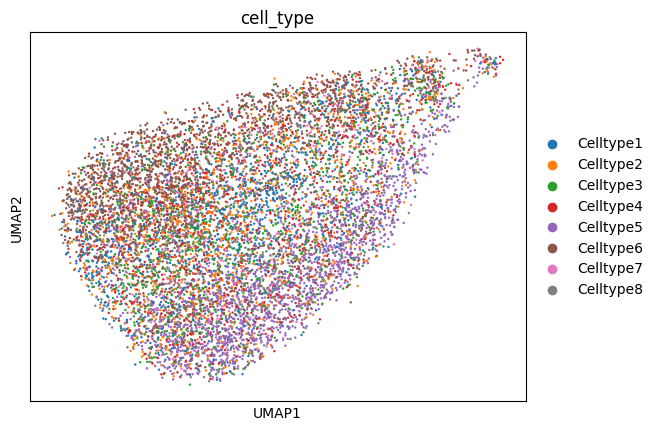

In [24]:
sc.pp.neighbors(adata,
                n_neighbors=5,
                use_rep='jepa_emb')
sc.tl.umap(adata)
sc.pl.umap(adata,
           color='cell_type')

### 3.1.3 Logistic regression

In [25]:
classification_metrics(adata,
                       label_col='cell_type',
                       classifier='logistic')

Test Accuracy: 0.76
Test F1 Score: 0.75
Train Accuracy: 0.82
Train F1 Score: 0.81


/nfs/users/nfs_s/sb75/.local/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


{'test_accuracy': 0.7585,
 'test_f1': 0.747935551999388,
 'train_accuracy': 0.815375,
 'train_f1': 0.808762354733927}

### 3.1.4 KNeighborsClassifier

In [26]:
classification_metrics(adata,
                       label_col='cell_type',
                       classifier='knn',
                       n_neighbors=5)

Test Accuracy: 0.42
Test F1 Score: 0.33
Train Accuracy: 0.53
Train F1 Score: 0.47


{'test_accuracy': 0.4195,
 'test_f1': 0.325367252404349,
 'train_accuracy': 0.527,
 'train_f1': 0.47017293247760666}

### 3.1.5 nmi&ari

In [27]:
clustering_metrics(adata,
                   label_col='cell_type')

INFO:jax._src.xla_bridge:Unable to initialize backend 'cuda': module 'jaxlib.xla_extension' has no attribute 'GpuAllocatorConfig'
INFO:jax._src.xla_bridge:Unable to initialize backend 'rocm': module 'jaxlib.xla_extension' has no attribute 'GpuAllocatorConfig'
INFO:jax._src.xla_bridge:Unable to initialize backend 'tpu': INVALID_ARGUMENT: TpuPlatform is not available.
INFO:jax._src.xla_bridge:Unable to initialize backend 'plugin': xla_extension has no attributes named get_plugin_device_client. Compile TensorFlow with //tensorflow/compiler/xla/python:enable_plugin_device set to true (defaults to false) to enable this.
NMI (Normalized Mutual Information): 0.20860778226249935
ARI (Adjusted Rand Index): 0.10051844414647801


{'nmi': 0.20860778226249935, 'ari': 0.10051844414647801}

## 3.2 Cell Type CLS

In [ ]:
params['emb']['retrieve_cell'] = True
params['emb']['retrieve_niche'] = False
params['emb']['retrieve_gene'] = False
params['emb']['weighted_average']=False
params['emb']['average']=False
params['emb']['cls']=True
adata = evaluation(params, train_dataset, test_dataset)

### 3.2.1 Feature Analysis

In [ ]:
similarity_matrix = cosine_similarity(adata.obsm['jepa_emb'])
similarity_matrix

### 3.2.2 Umap

In [ ]:
sc.pp.neighbors(adata, n_neighbors=5, use_rep='jepa_emb')
sc.tl.umap(adata)

# Plot the UMAP
sc.pl.umap(adata, color='cell_type')

### 3.2.3 Logistic regression

In [ ]:
classification_metrics(adata, label_col='cell_type', classifier='logistic')

### 3.2.4 KNeighborsClassifier

In [ ]:
classification_metrics(adata, label_col='cell_type', classifier='knn', n_neighbors=5)

### 3.2.5 nmi&ari

In [ ]:
clustering_metrics(adata,label_col='cell_type')

## 3.3 Cell Type weighted_average

In [ ]:
params['emb']['retrieve_cell'] = True
params['emb']['retrieve_niche'] = False
params['emb']['retrieve_gene'] = False
params['emb']['weighted_average']=True
params['emb']['average']=False
params['emb']['cls']=False
adata = evaluation(params, train_dataset, test_dataset)

### 3.3.1 Feature Analysis

In [ ]:
similarity_matrix = cosine_similarity(adata.obsm['jepa_emb'])
similarity_matrix

### 3.3.2 Umap

In [ ]:
sc.pp.neighbors(adata, n_neighbors=5, use_rep='jepa_emb')
sc.tl.umap(adata)

# Plot the UMAP
sc.pl.umap(adata, color='cell_type')

### 3.3.3 Logistic regression

In [ ]:
classification_metrics(adata, label_col='cell_type', classifier='logistic')

### 3.3.4 KNN

In [ ]:
classification_metrics(adata, label_col='cell_type', classifier='knn', n_neighbors=5)

### 3.3.5 nmi&ari

In [ ]:
clustering_metrics(adata,label_col='cell_type')

## 3.4 Niche Type Average

In [ ]:
params['emb']['retrieve_cell'] = False
params['emb']['retrieve_niche'] = True
params['emb']['retrieve_gene'] = False
params['emb']['weighted_average']=False
params['emb']['average']=True
params['emb']['cls']=False
adata = evaluation(params, train_dataset, test_dataset)

### 3.4.1 Feature Analysis

In [ ]:
similarity_matrix = cosine_similarity(adata.obsm['jepa_emb'])
similarity_matrix

### 3.4.2 Umap

In [ ]:
sc.pp.neighbors(adata, n_neighbors=5, use_rep='jepa_emb')
sc.tl.umap(adata)

# Plot the UMAP
sc.pl.umap(adata, color='niche_type')

### 3.4.3 Logistic regression

In [ ]:
classification_metrics(adata, label_col='niche_type', classifier='logistic')

### 3.4.4 KNN

In [ ]:
classification_metrics(adata, label_col='niche_type', classifier='knn', n_neighbors=5)

### 3.4.5 nmi&ari

In [ ]:
clustering_metrics(adata,label_col='niche_type')

## 3.5 Niche Type CLS

In [ ]:
params['emb']['retrieve_cell'] = False
params['emb']['retrieve_niche'] = True
params['emb']['retrieve_gene'] = False
params['emb']['weighted_average']=False
params['emb']['average']=False
params['emb']['cls']=True
adata = evaluation(params, train_dataset, test_dataset)

### 3.5.1 Feature Analysis

In [ ]:
similarity_matrix = cosine_similarity(adata.obsm['jepa_emb'])
similarity_matrix

### 3.5.2 Umap

In [ ]:
sc.pp.neighbors(adata, n_neighbors=5, use_rep='jepa_emb')
sc.tl.umap(adata)

# Plot the UMAP
sc.pl.umap(adata, color='niche_type')

### 3.5.3 Logistic regression

In [ ]:
classification_metrics(adata, label_col='niche_type', classifier='logistic')

### 3.5.4 KNN

In [ ]:
classification_metrics(adata, label_col='niche_type', classifier='knn', n_neighbors=5)

### 3.5.5 nmi&ari

In [ ]:
clustering_metrics(adata,label_col='niche_type')

## 3.6 Niche Type weighted_average

In [ ]:
params['emb']['retrieve_cell'] = False
params['emb']['retrieve_niche'] = True
params['emb']['retrieve_gene'] = False
params['emb']['weighted_average']=True
params['emb']['average']=False
params['emb']['cls']=False
adata = evaluation(params, train_dataset, test_dataset)

### 3.6.1 Feature Analysis

In [ ]:
similarity_matrix = cosine_similarity(adata.obsm['jepa_emb'])
similarity_matrix

### 3.6.2 Umap

In [ ]:
sc.pp.neighbors(adata, n_neighbors=5, use_rep='jepa_emb')
sc.tl.umap(adata)

# Plot the UMAP
sc.pl.umap(adata, color='niche_type')

### 3.6.3 Logistic regression

In [ ]:
classification_metrics(adata, label_col='niche_type', classifier='logistic')

### 3.6.4 KNN

In [ ]:
classification_metrics(adata, label_col='niche_type', classifier='knn', n_neighbors=5)

### 3.6.5 nmi&ari

In [ ]:
clustering_metrics(adata,label_col='niche_type')

## 3.7 Retrieve Gene

In [28]:
params['emb']['retrieve_cell'] = False
params['emb']['retrieve_niche'] = False
params['emb']['retrieve_gene'] = True
params['emb']['weighted_average'] = False
params['emb']['average'] = True
params['emb']['cls'] = False
adata = evaluation(params, train_dataset, test_dataset)

INFO:root:GeneTransformerEncoder(
  (gene_embed): Embedding(1108, 768, padding_idx=0)
  (seg_embed): Embedding(3, 768, padding_idx=0)
  (blocks): ModuleList(
    (0-2): 3 x Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=3072, out_features=768, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
)
INFO:root:Encountered exception when loading checkpoi

/nfs/users/nfs_s/sb75/.local/lib/python3.10/site-packages/torch/utils/data/dataloader.py:557: UserWarning: This DataLoader will create 18 worker processes in total. Our suggested max number of worker in current system is 4, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(_create_warning_msg(
40it [00:26,  1.53it/s]
10it [00:08,  1.19it/s]
... storing 'split' as categorical
... storing 'label_name' as categorical
... storing 'retrieve_label' as categorical
... storing 'cell_type' as categorical


AnnData has been successfully saved at: logs/Simulated_data_pred_depth_1_pred_emb_dim_768_enc_depth_3_n_targets_4_n_contexts_1_target_mask_size_19_context_mask_size_361_num_epochs_15_incl_cell_seq_incl_neighborhood_seq_total/extracted_features/gene_embedding_gene_id_332_average.h5ad


### 3.7.1 Feature Analysis

In [ ]:
similarity_matrix = cosine_similarity(adata.obsm['jepa_emb'])
similarity_matrix

### 3.7.2 Umap

In [29]:
adata.obs

,split,label_name,retrieve_label,retrieve_position_emb,retrieve_emb_from_layer,cell_type,gene_count
0,train,cell_type,retrieve_gene,False,2,Celltype5,0
1,train,cell_type,retrieve_gene,False,2,Celltype7,0
2,train,cell_type,retrieve_gene,False,2,Celltype4,1
3,train,cell_type,retrieve_gene,False,2,Celltype2,0
4,train,cell_type,retrieve_gene,False,2,Celltype2,0
...,...,...,...,...,...,...,...
9995,test,cell_type,retrieve_gene,False,2,Celltype5,0
9996,test,cell_type,retrieve_gene,False,2,Celltype6,0
9997,test,cell_type,retrieve_gene,False,2,Celltype5,0
9998,test,cell_type,retrieve_gene,False,2,Celltype5,0


In [30]:
adata = adata[adata.obs['gene_count'] != 0]

/software/cellgen/team205/sb75/envs/nichejepa/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/software/cellgen/team205/sb75/envs/nichejepa/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


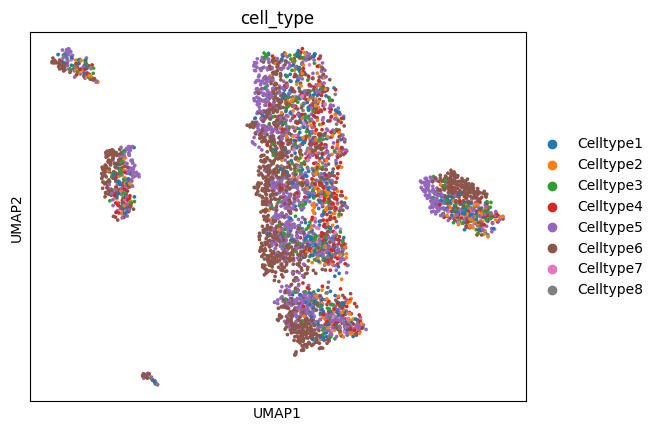

In [31]:
sc.pp.neighbors(adata,
                n_neighbors=5,
                use_rep='jepa_emb')
sc.tl.umap(adata)
sc.pl.umap(adata,
           color='cell_type')

# 4.Model Training With just_cell as True

## 4.1 Train Model

In [ ]:
params['data']['just_cell'] = True
params['data']['just_neighborhood'] = False
train(params, train_dataset, test_dataset)

# 5. Analysis With just_cell as True

## 5.1 Cell Type Average

In [ ]:
params['emb']['retrieve_cell'] = True
params['emb']['retrieve_niche'] = False
params['emb']['retrieve_gene'] = False
params['emb']['weighted_average']=False
params['emb']['average']=True
params['emb']['cls']=False
adata = evaluation(params, train_dataset, test_dataset)

### 5.1.1 Feature Analysis

In [ ]:
similarity_matrix = cosine_similarity(adata.obsm['jepa_emb'])
similarity_matrix

### 5.1.2 Umap

In [ ]:
sc.pp.neighbors(adata, n_neighbors=5, use_rep='jepa_emb')
sc.tl.umap(adata)

# Plot the UMAP
sc.pl.umap(adata, color='cell_type')

### 5.1.3 Logistic regression

In [ ]:
classification_metrics(adata, label_col='cell_type', classifier='logistic')

### 5.1.4 KNN

In [ ]:
classification_metrics(adata, label_col='cell_type', classifier='knn', n_neighbors=5)

### 5.1.5 nmi&ari

In [ ]:
clustering_metrics(adata,label_col='cell_type')

## 5.2 Cell Type CLS

In [ ]:
params['emb']['retrieve_cell'] = True
params['emb']['retrieve_niche'] = False
params['emb']['retrieve_gene'] = False
params['emb']['weighted_average']=False
params['emb']['average']=False
params['emb']['cls']=True
adata = evaluation(params, train_dataset, test_dataset)

### 5.2.1 Feature Analysis

In [ ]:
similarity_matrix = cosine_similarity(adata.obsm['jepa_emb'])
similarity_matrix

### 5.2.2 Umap

In [ ]:
sc.pp.neighbors(adata, n_neighbors=5, use_rep='jepa_emb')
sc.tl.umap(adata)

# Plot the UMAP
sc.pl.umap(adata, color='cell_type')

### 5.2.3 Logistic regression

In [ ]:
classification_metrics(adata, label_col='cell_type', classifier='logistic')

### 5.2.4 KNN

In [ ]:
classification_metrics(adata, label_col='cell_type', classifier='knn', n_neighbors=5)

### 5.2.5 nmi&ari

In [ ]:
clustering_metrics(adata,label_col='cell_type')

## 5.3 Cell Type weighted_average

In [ ]:
params['emb']['retrieve_cell'] = True
params['emb']['retrieve_niche'] = False
params['emb']['retrieve_gene'] = False
params['emb']['weighted_average']=True
params['emb']['average']=False
params['emb']['cls']=False
adata = evaluation(params, train_dataset, test_dataset)

### 5.3.1 Feature Analysis

In [ ]:
similarity_matrix = cosine_similarity(adata.obsm['jepa_emb'])
similarity_matrix

### 5.3.2 Umap

In [ ]:
sc.pp.neighbors(adata, n_neighbors=5, use_rep='jepa_emb')
sc.tl.umap(adata)

# Plot the UMAP
sc.pl.umap(adata, color='cell_type')

### 5.3.3 Logistic regression

In [ ]:
classification_metrics(adata, label_col='cell_type', classifier='logistic')

### 5.3.4 KNN

In [ ]:
classification_metrics(adata, label_col='cell_type', classifier='knn', n_neighbors=5)

### 5.3.5 nmi&ari

In [ ]:
clustering_metrics(adata,label_col='cell_type')

## 5.4 Retrieve Gene

In [ ]:
params['emb']['retrieve_cell'] = False
params['emb']['retrieve_niche'] = False
params['emb']['retrieve_gene'] = True
params['emb']['weighted_average']=False
params['emb']['average']=True
params['emb']['cls']=False
adata = evaluation(params, train_dataset, test_dataset)

### 5.4.1 Feature Analysis

In [ ]:
similarity_matrix = cosine_similarity(adata.obsm['jepa_emb'])
similarity_matrix

In [ ]:
adata = adata[adata.obs['gene_count']!=0]

### 5.4.2 Umap

In [ ]:
sc.pp.neighbors(adata, n_neighbors=5, use_rep='jepa_emb')
sc.tl.umap(adata)

# Plot the UMAP
sc.pl.umap(adata, color='cell_type')